
# B1 – Lingkungan Kerja dan Formulasi Masalah

**Proyek:** SIMUTEH – Sistem Identifikasi Kondisi Daun Teh

**Pertemuan:** 1

## Tujuan Praktikum

1. Menyiapkan lingkungan kerja untuk pengolahan citra digital.
2. Memeriksa pustaka yang digunakan dalam computer vision.
3. Memahami representasi citra digital dan urutan warna BGR/RGB.
4. Merumuskan permasalahan yang akan diselesaikan oleh sistem SIMUTEH.
5. Menyusun pipeline sistem dan mengidentifikasi risiko penggunaannya.


In [ ]:
!pip install opencv-python numpy matplotlib scikit-image pandas pillow

In [ ]:

# Import pustaka
import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage
import pandas as pd
from PIL import Image

print("Semua pustaka berhasil diimpor!")


Semua pustaka berhasil diimpor!


In [ ]:

# Pemeriksaan versi pustaka
print("OpenCV       :", cv2.__version__)
print("NumPy        :", np.__version__)
print("Matplotlib   :", plt.matplotlib.__version__)
print("Scikit-image :", skimage.__version__)
print("Pandas       :", pd.__version__)
print("Pillow       :", Image.__version__)


OpenCV       : 4.14.0
NumPy        : 2.1.3
Matplotlib   : 3.10.0
Scikit-image : 0.25.2
Pandas       : 2.2.3
Pillow       : 11.3.0


In [ ]:

# Membuat file requirements.txt
requirements = """
opencv-python==4.14.0
numpy==2.1.3
matplotlib==3.10.0
scikit-image==0.25.2
pandas==2.2.3
pillow==11.3.0
"""

with open("requirements.txt", "w") as file:
    file.write(requirements.strip())

print("File requirements.txt berhasil dibuat!")
print(requirements)


File requirements.txt berhasil dibuat!

opencv-python==4.14.0
numpy==2.1.3
matplotlib==3.10.0
scikit-image==0.25.2
pandas==2.2.3
pillow==11.3.0



In [ ]:
import os

os.makedirs("src", exist_ok=True)
os.makedirs("hasil", exist_ok=True)

print("Folder src dan hasil berhasil dibuat!")

Folder src dan hasil berhasil dibuat!


In [ ]:

%%writefile src/buat_dataset_sintetis.py

import os
import csv
import cv2
import numpy as np

SEED = 1026
N_PER_KELAS = 20
H, W = 480, 640

KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]

OUT = os.path.join("data", "sintetis")
rng = np.random.default_rng(SEED)


def gambar_daun(img, mask):
    cx = int(rng.integers(260, 380))
    cy = int(rng.integers(200, 280))
    ax = int(rng.integers(190, 240))
    ay = int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))

    hijau = np.array([
        rng.integers(35, 60),
        rng.integers(120, 150),
        rng.integers(45, 75)
    ])

    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360,
                hijau.tolist(), -1)
    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360,
                255, -1)

    t = np.deg2rad(sudut)
    p1 = (int(cx - ax * np.cos(t)), int(cy - ay * np.sin(t)))
    p2 = (int(cx + ax * np.cos(t)), int(cy + ay * np.sin(t)))

    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)

    for k in np.linspace(-0.7, 0.7, 6):
        bx = cx + k * ax * np.cos(t)
        by = cy + k * ax * np.sin(t)

        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)
            cv2.line(img, (int(bx), int(by)),
                     (int(ex), int(ey)), tulang, 1)

    return mask


def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    if kelas == "sehat":
        return

    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))
    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)

    ys, xs = np.where(mask_daun > 0)

    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))

        warna = [
            int(rng.integers(70, 100)),
            int(rng.integers(165, 190)),
            int(rng.integers(185, 210))
        ]

        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)

    mask_bercak &= mask_daun


def ganggu_cahaya(img, kondisi):
    f = img.astype(np.float32)

    if kondisi == "gelap":
        f = 255 * (f / 255) ** 2.0
    elif kondisi == "terang":
        f = 255 * (f / 255) ** 0.45
    elif kondisi == "kontras_rendah":
        f = 0.35 * f + 95
    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)
        f = f * gx[None, :, None]

    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)

    return np.clip(f, 0, 255).astype(np.uint8)


def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)

    baris = []
    nomor = 0

    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1

            latar = np.array([
                rng.integers(150, 190),
                rng.integers(170, 205),
                rng.integers(185, 215)
            ])

            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)
            img = cv2.add(
                img,
                rng.integers(0, 12, (H, W, 3)).astype(np.uint8)
            )

            m_daun = np.zeros((H, W), np.uint8)
            m_bercak = np.zeros((H, W), np.uint8)

            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)

            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]
            citra = ganggu_cahaya(bersih, kondisi)

            nama = f"teh_{nomor:03d}.png"

            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)

            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)

            baris.append([
                nama, kelas, kondisi, round(persen, 2)
            ])

    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow([
            "nama_file", "kelas", "kondisi_cahaya", "persen_bercak"
        ])
        w.writerows(baris)

    print(f"Selesai: {nomor} citra tersimpan di {OUT}")


if __name__ == "__main__":
    main()


Overwriting src/buat_dataset_sintetis.py


In [ ]:
!python src/buat_dataset_sintetis.py

Selesai: 60 citra tersimpan di data/sintetis


In [ ]:
import os

folder = "data/sintetis"

for nama in ["citra", "bersih", "mask_daun", "mask_bercak"]:
    jumlah = len(os.listdir(os.path.join(folder, nama)))
    print(f"{nama}: {jumlah} file")

print("Label CSV:", os.path.exists(os.path.join(folder, "label.csv")))

citra: 60 file
bersih: 60 file
mask_daun: 60 file
mask_bercak: 60 file
Label CSV: True


In [ ]:

%%writefile src/utils_cv.py

import cv2
import numpy as np
import matplotlib.pyplot as plt


def baca(path):
    """Membaca citra dan memberi pesan jika gagal."""
    img = cv2.imread(path)

    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")

    return img


def tampil(daftar, judul, baris=1, ukuran=(14, 4)):
    """Menampilkan beberapa citra berdampingan."""
    kolom = int(np.ceil(len(daftar) / baris))

    plt.figure(figsize=ukuran)

    for i, (im, jd) in enumerate(zip(daftar, judul)):
        plt.subplot(baris, kolom, i + 1)

        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)

        plt.title(jd)
        plt.axis("off")

    plt.tight_layout()


def kontras_bercak(kanal, mask_daun, mask_bercak):
    """Menghitung kontras bercak terhadap daun sehat."""
    k = kanal.astype(np.float64)

    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0

    if bercak.sum() == 0:
        return float("nan")

    return abs(k[bercak].mean() - k[sehat].mean()) / (
        k[sehat].std() + 1e-6
    )


def statistik(gray):
    """Ringkasan statistik intensitas citra."""
    return {
        "rerata": round(float(gray.mean()), 1),
        "simpangan_baku": round(float(gray.std()), 1),
        "min": int(gray.min()),
        "maks": int(gray.max()),
        "persen_gelap": round(100 * float((gray < 50).mean()), 1),
        "persen_terang": round(100 * float((gray > 205).mean()), 1)
    }


Overwriting src/utils_cv.py


In [ ]:

import sys
sys.path.append("src")

import cv2
import numpy as np
import skimage
import matplotlib.pyplot as plt

from utils_cv import baca, tampil

# Membaca citra sintetis
img = baca("data/sintetis/citra/teh_041.png")

# Memeriksa informasi citra
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Scikit-image:", skimage.__version__)

print("Shape:", img.shape)
print("Dtype:", img.dtype)
print("Min-maks:", img.min(), img.max())

print("Piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])


OpenCV: 4.14.0
NumPy: 2.1.3
Scikit-image: 0.25.2
Shape: (480, 640, 3)
Dtype: uint8
Min-maks: 0 255
Piksel (y=100, x=200) dalam urutan BGR: [191 206 214]


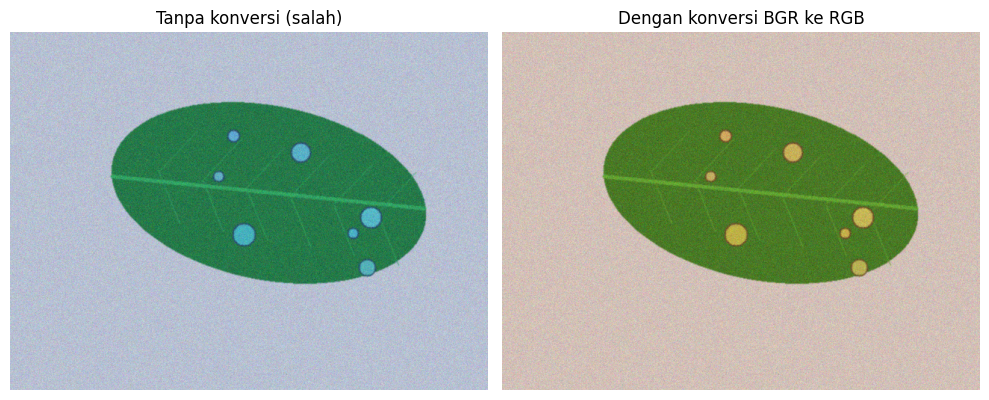

In [ ]:

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Tanpa konversi (salah)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB")
plt.axis("off")

plt.tight_layout()
plt.savefig("hasil/b1_bgr_rgb.png")
plt.show()





## 1. Formulasi Masalah

### Pernyataan Masalah

Bagi petani dan pihak yang melakukan pemeriksaan kualitas daun teh yang menghadapi kesulitan dalam mengidentifikasi kondisi daun serta tingkat keparahan bercak penyakit secara konsisten, kami membangun SIMUTEH (Sistem Identifikasi Mutu Daun Teh) yang menerima citra digital daun teh berwarna (RGB) dan menghasilkan klasifikasi kondisi daun menjadi sehat, bercak ringan, dan bercak berat, sehingga proses identifikasi kondisi daun teh dapat dilakukan secara lebih mudah dan terstruktur.



## 2. Pipeline Sistem SIMUTEH

### 1. Akuisisi Citra (Image Acquisition)
- **Masukan:** Daun teh sebagai objek yang akan diperiksa.
- **Proses:** Pengambilan gambar daun teh menggunakan kamera RGB dengan pencahayaan tertentu.
- **Keluaran:** Citra digital daun teh berwarna dalam format RGB/BGR.

### 2. Pra-pemrosesan (Pre-processing)
- **Masukan:** Citra digital daun teh.
- **Proses:** Mengubah ukuran citra, mengurangi derau, memperbaiki kualitas citra, dan menyesuaikan format warna.
- **Keluaran:** Citra daun teh yang telah dipersiapkan untuk analisis.

### 3. Segmentasi (Segmentation)
- **Masukan:** Citra hasil pra-pemrosesan.
- **Proses:** Memisahkan area daun dari latar belakang serta mengidentifikasi area bercak pada daun.
- **Keluaran:** Mask area daun dan mask area bercak.

### 4. Ekstraksi Fitur (Feature Extraction)
- **Masukan:** Citra daun dan hasil segmentasi.
- **Proses:** Mengambil karakteristik warna, tekstur, bentuk, serta persentase area bercak.
- **Keluaran:** Informasi fitur yang menggambarkan kondisi daun teh.

### 5. Klasifikasi (Classification)
- **Masukan:** Fitur citra daun teh.
- **Proses:** Mengelompokkan kondisi daun berdasarkan karakteristik dan tingkat keparahan bercak.
- **Keluaran:** Kelas sehat, bercak ringan, atau bercak berat.

### 6. Interpretasi Hasil (Interpretation)
- **Masukan:** Hasil klasifikasi.
- **Proses:** Menampilkan informasi kondisi dan tingkat keparahan bercak daun teh.
- **Keluaran:** Informasi hasil identifikasi kondisi daun teh yang mudah dipahami pengguna.


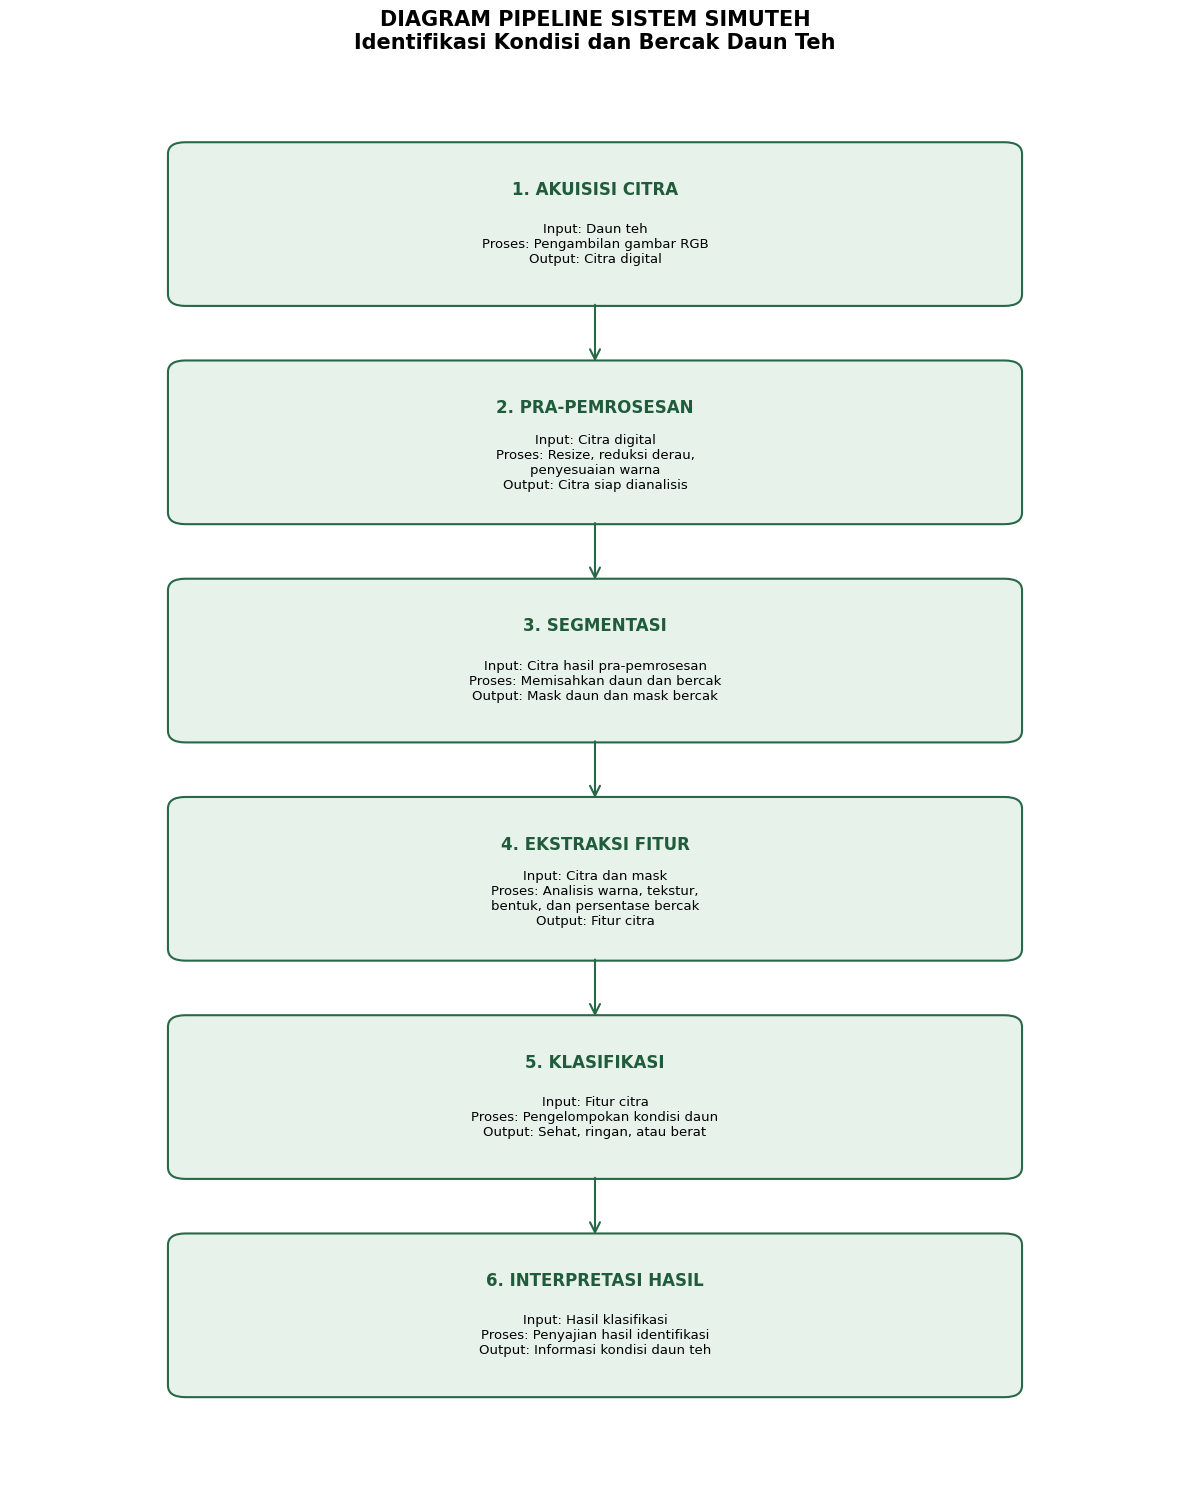

Diagram pipeline berhasil disimpan!


In [ ]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

tahapan = [
    ("1. AKUISISI CITRA",
     "Input: Daun teh\nProses: Pengambilan gambar RGB\nOutput: Citra digital"),

    ("2. PRA-PEMROSESAN",
     "Input: Citra digital\nProses: Resize, reduksi derau,\npenyesuaian warna\nOutput: Citra siap dianalisis"),

    ("3. SEGMENTASI",
     "Input: Citra hasil pra-pemrosesan\nProses: Memisahkan daun dan bercak\nOutput: Mask daun dan mask bercak"),

    ("4. EKSTRAKSI FITUR",
     "Input: Citra dan mask\nProses: Analisis warna, tekstur,\nbentuk, dan persentase bercak\nOutput: Fitur citra"),

    ("5. KLASIFIKASI",
     "Input: Fitur citra\nProses: Pengelompokan kondisi daun\nOutput: Sehat, ringan, atau berat"),

    ("6. INTERPRETASI HASIL",
     "Input: Hasil klasifikasi\nProses: Penyajian hasil identifikasi\nOutput: Informasi kondisi daun teh")
]

fig, ax = plt.subplots(figsize=(12, 15))
ax.set_xlim(0, 10)
ax.set_ylim(0, 18)
ax.axis("off")

posisi_y = [15.2, 12.4, 9.6, 6.8, 4.0, 1.2]

for i, (judul, isi) in enumerate(tahapan):
    y = posisi_y[i]

    kotak = FancyBboxPatch(
        (1.5, y), 7, 1.8,
        boxstyle="round,pad=0.15",
        linewidth=1.5,
        edgecolor="#286747",
        facecolor="#E7F3EA"
    )

    ax.add_patch(kotak)

    ax.text(
        5, y + 1.35, judul,
        ha="center", va="center",
        fontsize=12, fontweight="bold",
        color="#205B3B"
    )

    ax.text(
        5, y + 0.65, isi,
        ha="center", va="center",
        fontsize=9.5
    )

    if i < len(tahapan) - 1:
        panah = FancyArrowPatch(
            (5, y - 0.1),
            (5, posisi_y[i + 1] + 1.9),
            arrowstyle="->",
            mutation_scale=18,
            linewidth=1.5,
            color="#286747"
        )
        ax.add_patch(panah)

ax.set_title(
    "DIAGRAM PIPELINE SISTEM SIMUTEH\n"
    "Identifikasi Kondisi dan Bercak Daun Teh",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.tight_layout()
plt.savefig(
    "hasil/b1_pipeline.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Diagram pipeline berhasil disimpan!")



## 3. Identifikasi Risiko dan Mitigasi SIMUTEH

| Aspek | Risiko pada SIMUTEH | Mitigasi Awal |
|---|---|---|
| Privacy of Image (Privasi Citra) | Foto daun teh mungkin memuat informasi lokasi atau lingkungan milik pengguna. | Menggunakan citra daun teh yang relevan dan menghindari penyimpanan informasi pribadi yang tidak diperlukan. |
| Bias/Fairness (Bias dan Keadilan) | Sistem dapat menghasilkan klasifikasi yang kurang akurat pada kondisi pencahayaan atau variasi daun tertentu. | Menggunakan dataset dengan variasi kondisi pencahayaan dan tingkat bercak yang beragam. |
| Transparency (Transparansi) | Pengguna mungkin tidak mengetahui alasan sistem memberikan hasil klasifikasi tertentu. | Menampilkan hasil klasifikasi beserta informasi pendukung seperti persentase bercak. |
| Data Security (Keamanan Data) | Dataset dan hasil pengolahan citra berisiko diakses atau diubah oleh pihak yang tidak berwenang. | Membatasi akses data dan menyimpan dataset pada tempat yang aman. |
| Social Impact (Dampak Sosial) | Kesalahan klasifikasi dapat memengaruhi keputusan pengguna dalam menilai kondisi daun teh. | Menjadikan hasil sistem sebagai alat bantu pemeriksaan, bukan satu-satunya dasar pengambilan keputusan. |
| Traceability (Ketertelusuran) | Hasil klasifikasi sulit diperiksa kembali jika data dan proses pengolahan tidak terdokumentasi. | Menyimpan dataset, label, parameter, dan hasil pengolahan secara terstruktur. |



## 4. Analisis dan Refleksi

### P1.1 – Semantic Gap

Semantic gap merupakan perbedaan antara informasi visual yang ditangkap komputer dalam bentuk piksel dengan makna yang dipahami manusia.

Pada SIMUTEH, komputer menerima citra daun teh berupa kumpulan nilai piksel, sedangkan manusia dapat memahami kondisi daun sebagai sehat, bercak ringan, atau bercak berat. Oleh karena itu, diperlukan proses pengolahan citra dan ekstraksi fitur agar komputer dapat mengenali karakteristik daun teh dan mengelompokkannya sesuai kondisi.

### P1.2 – Sumber Variabilitas Citra

Tiga sumber variabilitas yang dapat memengaruhi hasil identifikasi SIMUTEH adalah:

1. **Pencahayaan:** Perbedaan intensitas cahaya dapat membuat warna daun terlihat lebih gelap atau terang. Variasi ini ditangani pada tahap pra-pemrosesan melalui penyesuaian pencahayaan dan normalisasi citra.

2. **Derau (Noise):** Gangguan pada citra dapat mengurangi kejelasan detail daun dan bercak. Variasi ini ditangani pada tahap pra-pemrosesan melalui metode reduksi derau atau filtering.

3. **Latar Belakang:** Warna atau tekstur latar belakang dapat mengganggu proses identifikasi area daun. Variasi ini ditangani pada tahap segmentasi untuk memisahkan objek daun dari latar belakang.

### P1.3 – Pengaruh BGR dan RGB

OpenCV menggunakan urutan warna BGR, sedangkan Matplotlib menggunakan urutan RGB. Jika citra BGR langsung ditampilkan menggunakan Matplotlib tanpa konversi, warna yang dihasilkan menjadi tidak sesuai.

Perbedaan tersebut dapat memengaruhi analisis fitur warna pada pertemuan berikutnya, karena nilai kanal warna yang digunakan untuk ekstraksi fitur dapat tertukar. Oleh karena itu, konversi BGR ke RGB perlu dilakukan ketika menampilkan citra menggunakan Matplotlib.

### P1.4 – Dampak Kesalahan Klasifikasi

Jika daun sehat diklasifikasikan sebagai daun dengan bercak berat, pengguna dapat menganggap daun tersebut memiliki masalah padahal kondisinya sehat. Sebaliknya, jika daun dengan bercak berat diklasifikasikan sebagai daun sehat, kondisi daun yang sebenarnya membutuhkan pemeriksaan lebih lanjut dapat terabaikan.

Kesalahan tersebut dapat mengurangi kepercayaan pengguna terhadap sistem SIMUTEH. Oleh karena itu, sistem perlu diuji menggunakan data yang bervariasi, dievaluasi tingkat akurasinya, dan digunakan sebagai alat bantu identifikasi, bukan sebagai satu-satunya dasar keputusan.


In [ ]:

import os

def tampilkan_folder(folder, indent=0):
    for nama in sorted(os.listdir(folder)):
        path = os.path.join(folder, nama)

        print(" " * indent + ("📁 " if os.path.isdir(path) else "📄 ") + nama)

        if os.path.isdir(path):
            tampilkan_folder(path, indent + 4)

print("STRUKTUR PROJECT SIMUTEH")
tampilkan_folder(".")


STRUKTUR PROJECT SIMUTEH
📁 data
    📁 sintetis
        📁 bersih
            📄 teh_001.png
            📄 teh_002.png
            📄 teh_003.png
            📄 teh_004.png
            📄 teh_005.png
            📄 teh_006.png
            📄 teh_007.png
            📄 teh_008.png
            📄 teh_009.png
            📄 teh_010.png
            📄 teh_011.png
            📄 teh_012.png
            📄 teh_013.png
            📄 teh_014.png
            📄 teh_015.png
            📄 teh_016.png
            📄 teh_017.png
            📄 teh_018.png
            📄 teh_019.png
            📄 teh_020.png
            📄 teh_021.png
            📄 teh_022.png
            📄 teh_023.png
            📄 teh_024.png
            📄 teh_025.png
            📄 teh_026.png
            📄 teh_027.png
            📄 teh_028.png
            📄 teh_029.png
            📄 teh_030.png
            📄 teh_031.png
            📄 teh_032.png
            📄 teh_033.png
            📄 teh_034.png
            📄 teh_035.png
            📄 teh_036.png


In [ ]:

import os
import pandas as pd

folder = "data/sintetis"

# Memeriksa jumlah citra
for subfolder in ["citra", "bersih", "mask_daun", "mask_bercak"]:
    path = os.path.join(folder, subfolder)
    jumlah = len([
        f for f in os.listdir(path)
        if f.lower().endswith(".png")
    ])
    print(f"Jumlah {subfolder}: {jumlah}")

# Memeriksa label
label = pd.read_csv(os.path.join(folder, "label.csv"))

print("\nJumlah seluruh data:", len(label))
print("\nDistribusi kelas:")
print(label["kelas"].value_counts())

print("\nDistribusi kondisi cahaya:")
print(label["kondisi_cahaya"].value_counts())

print("\nContoh isi label:")
display(label.head())


Jumlah citra: 60
Jumlah bersih: 60
Jumlah mask_daun: 60
Jumlah mask_bercak: 60

Jumlah seluruh data: 60

Distribusi kelas:
kelas
sehat     20
ringan    20
berat     20
Name: count, dtype: int64

Distribusi kondisi cahaya:
kondisi_cahaya
normal            12
gelap             12
terang            12
kontras_rendah    12
bayangan          12
Name: count, dtype: int64

Contoh isi label:


,nama_file,kelas,kondisi_cahaya,persen_bercak
0,teh_001.png,sehat,normal,0.0
1,teh_002.png,sehat,gelap,0.0
2,teh_003.png,sehat,terang,0.0
3,teh_004.png,sehat,kontras_rendah,0.0
4,teh_005.png,sehat,bayangan,0.0


In [ ]:

print("File hasil B1:")

for file in [
    "requirements.txt",
    "src/buat_dataset_sintetis.py",
    "src/utils_cv.py",
    "hasil/b1_bgr_rgb.png",
    "hasil/b1_pipeline.png"
]:
    print(
        ("ADA   " if os.path.exists(file) else "BELUM ADA"),
        file
    )


File hasil B1:
ADA    requirements.txt
ADA    src/buat_dataset_sintetis.py
ADA    src/utils_cv.py
ADA    hasil/b1_bgr_rgb.png
ADA    hasil/b1_pipeline.png


In [ ]:
import os

print("Lokasi saat ini:", os.getcwd())
print("Isi folder /content:")
print(os.listdir("/content"))

Lokasi saat ini: /content/simuteh-2330511026
Isi folder /content:
['.config', 'dataset_simuteh.zip', 'simuteh-2330511026', 'sample_data']


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    if "data" in dirs:
        print("Folder data ditemukan:", os.path.join(root, "data"))

Folder data ditemukan: /content/simuteh-2330511026/data


In [ ]:
import shutil

shutil.make_archive(
    "/content/dataset_simuteh",
    "zip",
    root_dir="/content/simuteh-2330511026",
    base_dir="data"
)

print("ZIP dataset berhasil dibuat!")

ZIP dataset berhasil dibuat!


In [ ]:
from google.colab import files

files.download("/content/dataset_simuteh.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>